In [1]:
import numpy as np
from jedi.third_party.typeshed.stubs.tensorflow.tensorflow.keras.optimizers.legacy import Adam

from src.datasets import load_examples_mnist
from src.network import Network
from src.optimizers import MomentumOptimizer, AdamOptimizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, LabelBinarizer
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

In [2]:
X, y = load_examples_mnist(n_samples=10000)
X_test, y_test = load_examples_mnist(n_samples=10000,
                                     images_path='data/mnist-handwritten-images/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte',
                                     labels_path='data/mnist-handwritten-images/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.9, random_state=1)

sizes = [X_train.shape[1], 100, 10]
activation_functions = ['sigmoid', 'sigmoid']
mini_batch_size = 10
max_epochs = 60

scaler = StandardScaler()
encoder = LabelBinarizer()

X_train_t = scaler.fit_transform(X_train).T
y_train_t = encoder.fit_transform(y_train).T
X_val_t = scaler.transform(X_val).T
y_val_t = encoder.transform(y_val).T

In [3]:
def plot_train_test_accuracy(net: Network, ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()
    training_accuracy = np.array(net.training_accuracy)*100
    test_accuracy = np.array(net.val_accuracy)*100
    epochs = np.arange(len(training_accuracy))
    ax.plot(epochs,training_accuracy,c='blue',label='Training accuracy')
    ax.plot(epochs,test_accuracy,c='red',label='Test accuracy')
    ax.grid(visible=True, axis="both", which="major", linestyle="--", linewidth="0.5")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("Validation Curve")

## Momentum and ADAM

In [4]:
net = Network(sizes, activation_functions, mini_batch_size=mini_batch_size, cost="cross_entropy", init_method="naive",
              max_epochs=max_epochs, random_state=1, verbose=True, monitor_cost=True, monitor_accuracy=True, learning_rate=0.009)
opts = [None, MomentumOptimizer(0.9), AdamOptimizer()]
colors = ['orange', 'red', 'blue']
train_costs = []
val_costs = []
for opt in opts:
    net.set_params(**dict(optimizer=opt))
    net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
    train_costs.append(net.train_cost_cache)
    val_costs.append(net.val_cost_cache)

epoch: 0, cost: 3.708471495112095
train score: 0.268, val score: 0.26511111111111113
 
epoch: 1, cost: 2.987232072769525
train score: 0.431, val score: 0.39811111111111114
 
epoch: 2, cost: 2.783381256677996
train score: 0.556, val score: 0.4885555555555556
 
epoch: 3, cost: 2.6053005559707594
train score: 0.627, val score: 0.5642222222222222
 
epoch: 4, cost: 2.448653909783153
train score: 0.664, val score: 0.6074444444444445
 
epoch: 5, cost: 2.3058353761992163
train score: 0.703, val score: 0.6443333333333333
 
epoch: 6, cost: 2.1780415296651365
train score: 0.733, val score: 0.6635555555555556
 
epoch: 7, cost: 2.0623266708993557
train score: 0.762, val score: 0.6974444444444444
 
epoch: 8, cost: 1.9592736404998161
train score: 0.768, val score: 0.7067777777777777
 
epoch: 9, cost: 1.8651127852509208
train score: 0.782, val score: 0.7192222222222222
 
epoch: 10, cost: 1.7796461282449036
train score: 0.795, val score: 0.7322222222222222
 
epoch: 11, cost: 1.70206288668783
train scor

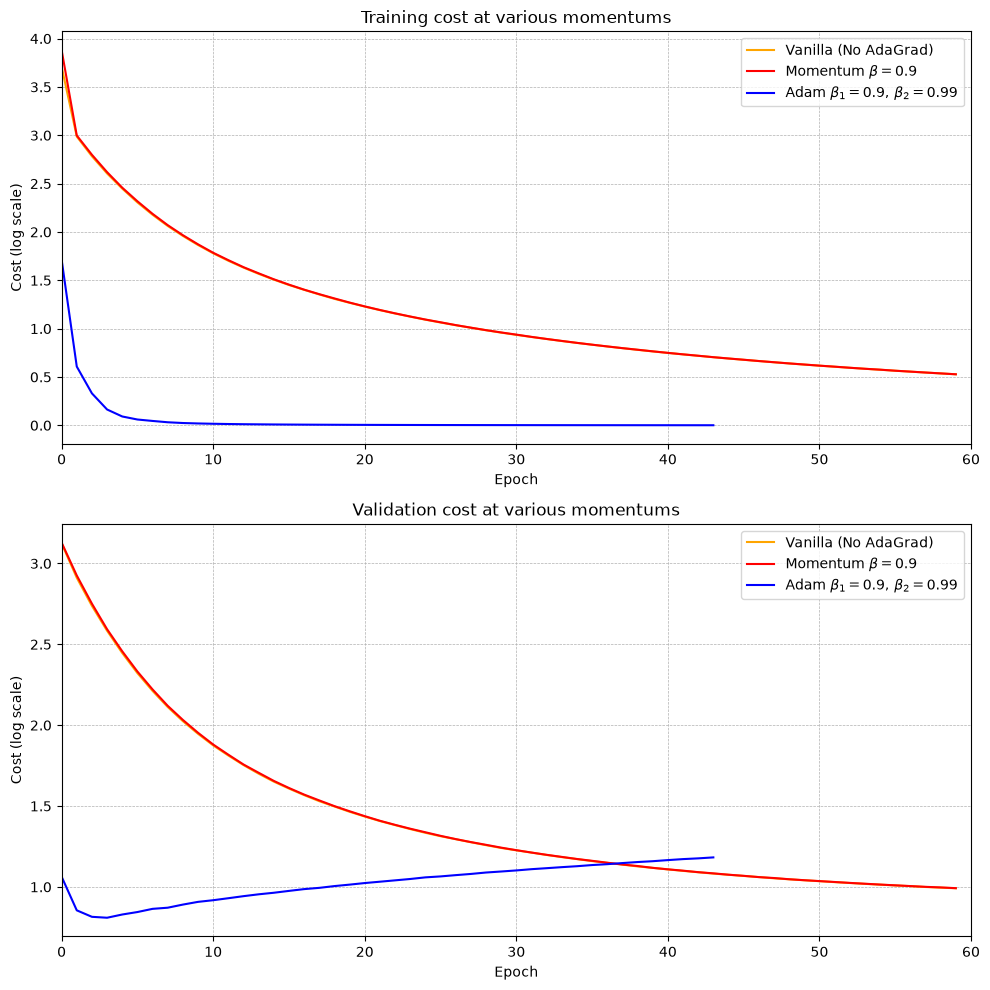

In [5]:
fig,axs = plt.subplots(2,1,figsize=(10,10))
labels = [rf"Vanilla (No AdaGrad)",
          rf"Momentum $\beta=0.9$",
          rf"Adam $\beta_1=0.9,\, \beta_2=0.99$"]
for color, label, train_cost, val_cost in zip(colors, labels, train_costs, val_costs):
    axs[0].plot(range(len(train_cost)), train_cost, '-', c=color, label=label, mfc=color, mec='k')
    axs[1].plot(range(len(val_cost)), val_cost, '-', c=color, label=label, mfc=color, mec='k')

titles = ['Training cost at various momentums', 'Validation cost at various momentums']
xlims = [(0,60),(0,60)]
yscales = ['linear', 'linear']
for ax,title,xlim,yscale in zip(axs.flatten(), titles, xlims, yscales):
    ax.grid(visible=True, axis="both", which="major", linestyle="--", linewidth="0.5")
    ax.set_xlim(xlim)
    ax.set_xlabel('Epoch')
    ax.set_ylabel("Cost (log scale)")
    ax.set_yscale(yscale)
    ax.legend()
    ax.set_title(title)

plt.tight_layout()
plt.show()

## Hyperparameter tuning

In [13]:
X, y = load_examples_mnist(n_samples=60000)
X_test, y_test = load_examples_mnist(n_samples=10000,
                                     images_path='data/mnist-handwritten-images/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte',
                                     labels_path='data/mnist-handwritten-images/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.9, random_state=1)

scaler = StandardScaler()
encoder = LabelBinarizer()

X_train_t = scaler.fit_transform(X_train).T
y_train_t = encoder.fit_transform(y_train).T
X_val_t = scaler.transform(X_val).T
y_val_t = encoder.transform(y_val).T

In [120]:
sizes = [X_train.shape[1], 30, 10]
activation_functions = ['sigmoid', 'sigmoid']
mini_batch_size = 10
max_epochs = 32

net = Network(sizes, activation_functions, mini_batch_size=mini_batch_size, cost="cross_entropy", init_method="naive",
              max_epochs=32, random_state=1, verbose=False, monitor_cost=True, monitor_accuracy=True, learning_rate=0.1,
              penalty='l2', alpha=8.6)

net.fit(X_train_t, y_train_t, X_val_t, y_val_t)

,sizes,"[784, 30, ...]"
,activation_functions,"['sigmoid', 'sigmoid']"
,cost,'cross_entropy'
,penalty,'l2'
,alpha,8.6
,random_state,1
,max_epochs,32
,monitor_cost,True
,monitor_accuracy,True
,learning_rate,0.1
,mini_batch_size,10


### Learning Rate

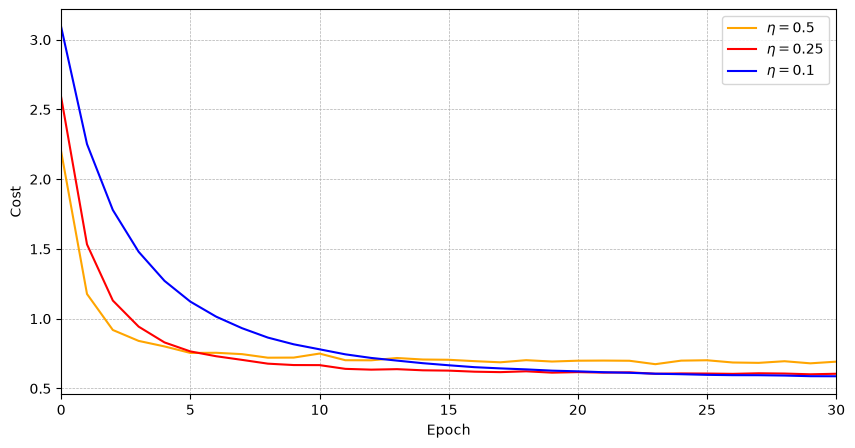

In [122]:
cost = net.train_cost_cache
lrs = [0.5, 0.25, 0.1]
colors = ['orange', 'red', 'blue']
labels = [rf'$\eta = {lr}$' for lr in lrs]
fig, axs = plt.subplots(figsize=(10,5))
for lr, color, label in zip(lrs, colors, labels):
    net.set_params(**dict(learning_rate=lr))
    net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
    cost = net.train_cost_cache
    axs.plot(range(32),cost,color=color,label=label)
axs.set_xlabel("Epoch")
axs.set_ylabel("Cost")
axs.set_xlim(0,30)
axs.grid(visible=True, axis="both", which="major", linestyle="--", linewidth="0.5")
axs.legend()
plt.show()

Selected learning rate: $\eta=0.1$

### Number of Epochs

In [125]:
net = Network(sizes, activation_functions, mini_batch_size=mini_batch_size, cost="cross_entropy", init_method="naive",
              max_epochs=400, random_state=1, verbose=False, monitor_cost=True, monitor_accuracy=True, learning_rate=0.25,
              penalty='l2', alpha=8.6)

net.set_params(**dict(early_stop_patience=10))
net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
print(f'n_epochs: {net.n_epochs}, score: {net.score(X_val_t, y_val_t):.2%}')

n_epochs: 23, score: 86.57%


Selected early stop patience: 10

### Regularization Parameter $\alpha$

In [165]:
net = Network(sizes, activation_functions, mini_batch_size=mini_batch_size, cost="cross_entropy", init_method="naive",
              max_epochs=400, early_stop_patience=10, random_state=1, verbose=False, monitor_cost=True, monitor_accuracy=True, learning_rate=0.25,
              penalty='l2', alpha=8.6)

net.set_params(**dict(alpha=9))
net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
print(f'val score: {net.score(X_val_t, y_val_t):.2%}')

val score: 86.58%


Selected regularization parameter: $\alpha=8.6$

### Architecture Change

In [290]:
sizes = [X_train.shape[1], 400, 200, 60, 10]
activation_functions = ['relu', 'relu', 'sigmoid', 'sigmoid']
mini_batch_size = 10

adam = AdamOptimizer()
net = Network(sizes, activation_functions, mini_batch_size=mini_batch_size, cost="cross_entropy", init_method="naive",
              max_epochs=400, random_state=1, verbose=True, monitor_cost=True, monitor_accuracy=True, learning_rate=0.25,
              penalty='l2', alpha=9, early_stop_patience=10, learning_schedule_patience=5)

net.fit(X_train_t, y_train_t, X_val_t, y_val_t)
print(f'val score: {net.score(X_val_t, y_val_t):.2%}')

epoch: 0, cost: 2.2626319112509505
train score: 0.7648333333333334, val score: 0.7401296296296296
 
epoch: 1, cost: 1.0744073452365204
train score: 0.8248333333333333, val score: 0.8014629629629629
 
epoch: 2, cost: 0.6521739148190814
train score: 0.8856666666666667, val score: 0.8618148148148148
 
epoch: 3, cost: 0.5022818939307618
train score: 0.8366666666666667, val score: 0.8197407407407408
 
epoch: 4, cost: 0.4435085588864983
train score: 0.8398333333333333, val score: 0.8157037037037037
 
epoch: 5, cost: 0.3869851975845101
train score: 0.887, val score: 0.866462962962963
 
epoch: 6, cost: 0.36961443998330823
train score: 0.8001666666666667, val score: 0.7831111111111111
 
epoch: 7, cost: 0.429103901465449
train score: 0.8361666666666666, val score: 0.8152037037037037
 
epoch: 8, cost: 0.3813232139658794
train score: 0.8908333333333334, val score: 0.8674259259259259
 
epoch: 9, cost: 0.3120912677243998
train score: 0.8121666666666667, val score: 0.7923888888888889
 
epoch: 10, cos